<a href="https://colab.research.google.com/github/all3048/Beginning-Bioinformatics/blob/AncD1/Stage1_sequence_set_AncD1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1a — Assembling the AncD1 sequence set

**Goal:** produce one curated FASTA file containing AncD1, every kinetically
characterized relative we can find, a redundancy-reduced set of homologs, and an
outgroup for rooting. That file is the input to the alignment and tree.

**Do not skip Step 1.1.** The sequence in `AncD1 Gene Sequence DO NOT MODIFY.docx`
is the *expression construct*: a 6xHis/SUMO tag fused to AncD1. The first 99 residues
are tag, ending in the Gly-Gly motif that SUMO protease cleaves. Mature AncD1 is the
last 333 residues.

If you BLAST the full 432-residue construct you get two problems:
1. SUMO/ubiquitin-fold proteins come back as "homologs" and pollute the tree.
2. Every residue number is shifted by +99 relative to the FGD structural literature,
   so your candidate residues won't match anything anyone has published.

Run time: the BLAST step takes 5-15 minutes. Everything else is fast.

## Step 1.0 — Install dependencies

In [1]:
!pip install -q biopython
!apt-get -qq install -y cd-hit > /dev/null 2>&1
print("done")

done


In [2]:
import os, time, json, textwrap, urllib.request, urllib.parse
from collections import OrderedDict
from Bio import SeqIO, Entrez
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

# NCBI requires an email address to identify you as the requester.
EMAIL = "all3048@mavs.uta.edu"   # <-- fill this in before running
Entrez.email = EMAIL

WORK = "/content/ancd1_phylo"
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
print("working in", os.getcwd())

working in /content/ancd1_phylo


## Step 1.1 — The query sequence

Mature AncD1, tag removed. The assertions below are a guard: if you ever paste in a
different construct, they fail loudly instead of silently producing a shifted alignment.

In [3]:
# Full construct as it appears in the gene file (His/SUMO + AncD1)
ANCD1_CONSTRUCT = (
    "MMSDSEVNQEAKPEVKPEVKPETHINLKVSDGSSEIFFKIKKTTPLRRLMEAFAKRQGKEMDSLRFLYDGIRIQADQ"
    "TPEDLDMEDNDIIEAHREQIGGMLRFGYKASAEQFAPRELLDYGVLAEEVGFDSVFISDHLQPWRHDGGHAPAALAW"
    "LGALGARTERVVMGTSVLTPTFRYHPAIVAQAFATLGSLYPGRVILGVGTGEAMNEVPLGMEWPDGKVRFARLKEAV"
    "QVIKRLWTEDRPVTFEGDYYRLDKATIYDKPSTPVPIYIAGSGPAATKLAGRIGDGYITTSGKGPELYTDTLLPALR"
    "EGAEKAGRDPEDVDLMIEVKVSFDPDREKAMEATRFWGALALTPEEKHGVEDPIEMQRLADALPTEATAKRFIVSTD"
    "PDEHVARIKRYVDMGFTHLVFHAPGPDQARFLELYGEEILPRLRARV"
)

# SUMO (Smt3) ends in the diglycine that the protease cleaves. Everything after is AncD1.
SUMO_END = "HREQIGG"
cut = ANCD1_CONSTRUCT.find(SUMO_END) + len(SUMO_END)
TAG      = ANCD1_CONSTRUCT[:cut]
ANCD1    = ANCD1_CONSTRUCT[cut:]

assert len(ANCD1_CONSTRUCT) == 432, "construct length changed - check the gene file"
assert len(TAG)   == 99,  f"tag is {len(TAG)} aa, expected 99"
assert len(ANCD1) == 333, f"mature AncD1 is {len(ANCD1)} aa, expected 333"
assert ANCD1.startswith("MLRFGYKAS"), "mature sequence does not start as expected"
assert ANCD1.endswith("LRARV"),       "mature sequence does not end as expected"

print(f"tag   : {len(TAG)} aa  ...{TAG[-12:]}")
print(f"AncD1 : {len(ANCD1)} aa  {ANCD1[:30]}...{ANCD1[-10:]}")
print()
print("Mature AncD1 is ~333 aa, consistent with M. tuberculosis FGD1 (~336 aa).")

with open("query_AncD1.fasta","w") as fh:
    fh.write(">AncD1\n")
    for i in range(0, len(ANCD1), 60):
        fh.write(ANCD1[i:i+60] + "\n")
print("\nwrote query_AncD1.fasta")

tag   : 99 aa  ...DIIEAHREQIGG
AncD1 : 333 aa  MLRFGYKASAEQFAPRELLDYGVLAEEVGF...EILPRLRARV

Mature AncD1 is ~333 aa, consistent with M. tuberculosis FGD1 (~336 aa).

wrote query_AncD1.fasta


## Step 1.2 — The characterized reference panel

These are the enzymes with published function. They are what makes the tree
*interpretable* — without them it's just topology. Accessions come from Mascotti et al.
2018 (Sci Rep 8:17571), which defined the DH1/DH2/DH3 clades AncD1 sits at the base of.

| Accession | Enzyme | Clade | Why it's here |
|---|---|---|---|
| P9WNE1 | FGD1, *M. tuberculosis* | DH2 (FGD) | G6P-specific; structure 3B4Y |
| P96809 | FGD2, *M. tuberculosis* | DH2 (FGD) | second Mtb paralog |
| Q0RVH7 | Rh-FGD1, *R. jostii* RHA1 | DH2 (FGD) | characterized; structure 5LXE |
| E9V3D1 | FSD-Noca | DH3 (FSD) | promiscuous clade |
| WP_035860858.1 | FSD-Cryar, *C. arvum* | DH3 (FSD) | kinetically characterized |
| O93734 | Adf, *M. thermophilus* | DH1 (ADH) | F420 alcohol dehydrogenase; 1RHC |
| Q7TXK4 | phthiodiolone ketoreductase, *M. bovis* | DH1 (ADH) | |
| E6SIZ8 | alanine racemase, *T. marianensis* | — | **outgroup** used by Mascotti for rooting |

Two deliberate departures from Mascotti 2018, both needing a line in the methods:

1. **FSD-Cryar** is listed there as "FGD-Cryar." Reassigned on the basis of the later
   kinetic characterization — cite that paper as the justification.
2. **EGD40158.1 is excluded.** E9V3D1 is the correct accession for the *Nocardioides*
   enzyme, so only that entry is used.

Without those two sentences, anyone comparing your Figure 1 to Mascotti's Figure 5 will
read the differences as mis-assignment rather than correction.

In [4]:
REFERENCES = [
    # (accession, source, short_label, clade, note)
    ("P9WNE1",         "uniprot", "FGD1_Mtub",    "DH2_FGD",  "G6P-specific; PDB 3B4Y"),
    ("P96809",         "uniprot", "FGD2_Mtub",    "DH2_FGD",  "Mtb paralog"),
    ("Q0RVH7",         "uniprot", "FGD1_Rjos",    "DH2_FGD",  "PDB 5LXE"),
    ("E9V3D1",         "uniprot", "FSD_Noca",     "DH3_FSD",  "promiscuous clade"),
    ("O93734",         "uniprot", "Adf_Mthe",     "DH1_ADH",  "F420 alcohol DH; PDB 1RHC"),
    ("Q7TXK4",         "uniprot", "PtdKR_Mbov",   "DH1_ADH",  "phthiodiolone ketoreductase"),
    ("E6SIZ8",         "uniprot", "AlaRac_Tmar",  "OUTGROUP", "rooting outgroup"),
    ("WP_035860858.1", "ncbi",    "FSD_Cryar",    "DH3_FSD",  "kinetically characterized"),
]

MIN_OK, MAX_OK = 150, 600          # plausible length for anything in this panel

def _fetch_url(url):
    req = urllib.request.Request(url, headers={"User-Agent": "colab-phylo"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return r.read().decode()

def _parse_fasta(txt):
    txt = (txt or "").strip()
    if not txt or not txt.startswith(">"):
        return "", ""
    lines = txt.split("\n")
    return "".join(l.strip() for l in lines[1:] if not l.startswith(">")), lines[0]

def fetch_uniprot(acc):
    """Try the live entry, then a search that follows secondary/merged accessions,
    then UniParc, which retains deleted sequences."""
    for url in (
        f"https://rest.uniprot.org/uniprotkb/{acc}.fasta",
        f"https://rest.uniprot.org/uniprotkb/search?query=accession:{acc}&format=fasta",
        f"https://rest.uniprot.org/uniparc/search?query={acc}&format=fasta&size=1",
    ):
        try:
            seq, hdr = _parse_fasta(_fetch_url(url))
            if seq:
                tag = "" if "uniprotkb/" + acc in url else "  [via fallback]"
                return seq, hdr + tag
        except Exception:
            pass
    return "", ""

def fetch_ncbi(acc):
    h = Entrez.efetch(db="protein", id=acc, rettype="fasta", retmode="text")
    txt = h.read(); h.close()
    return _parse_fasta(txt)

ref_records, problems = [], []
for acc, src, label, clade, note in REFERENCES:
    try:
        seq, header = (fetch_uniprot(acc) if src == "uniprot" else fetch_ncbi(acc))
    except Exception as e:
        seq, header = "", f"{type(e).__name__}: {e}"

    if not seq:
        print(f"  EMPTY  {label:14s} {acc:16s} nothing returned")
        problems.append((label, acc, "empty response - accession may be obsolete"))
        continue
    if not (MIN_OK <= len(seq) <= MAX_OK):
        print(f"  ODD    {label:14s} {acc:16s} {len(seq):4d} aa  <-- outside {MIN_OK}-{MAX_OK}")
        problems.append((label, acc, f"implausible length {len(seq)}"))

    ref_records.append(SeqRecord(Seq(seq), id=f"{label}|{acc}|{clade}", description=note))
    note_tag = "  [via fallback]" if "fallback" in header else ""
    print(f"  OK     {label:14s} {acc:16s} {len(seq):4d} aa{note_tag}")
    time.sleep(0.4)

SeqIO.write(ref_records, "references.fasta", "fasta")
print(f"\nwrote references.fasta  ({len(ref_records)}/{len(REFERENCES)} usable)")

if problems:
    print("\n*** PROBLEMS - do not continue until these are resolved:")
    for label, acc, why in problems:
        print(f"    {label} ({acc}): {why}")
    print("\n    For an obsolete accession, open https://www.uniprot.org/uniprotkb/"
          + problems[0][1] + " in a browser - UniProt will name the entry it merged into.")

  OK     FGD1_Mtub      P9WNE1            336 aa
  OK     FGD2_Mtub      P96809            360 aa
  OK     FGD1_Rjos      Q0RVH7            335 aa
  OK     FSD_Noca       E9V3D1            334 aa  [via fallback]
  OK     Adf_Mthe       O93734            330 aa
  OK     PtdKR_Mbov     Q7TXK4            381 aa
  OK     AlaRac_Tmar    E6SIZ8            230 aa
  OK     FSD_Cryar      WP_035860858.1    332 aa

wrote references.fasta  (8/8 usable)


### Sanity check the panel

FGD/FSD/ADH family members should all land in the 300-400 aa range. Anything far outside
that is either the wrong accession or a fusion protein, and should be investigated before
it goes into the alignment. The outgroup (alanine racemase) is *expected* to be different —
that's the point of an outgroup.

In [5]:
for rec in ref_records:
    label, acc, clade = rec.id.split("|")
    flag = ""
    if clade != "OUTGROUP" and not (290 <= len(rec.seq) <= 420):
        flag = "  <-- CHECK: unexpected length for this family"
    print(f"{label:14s} {clade:9s} {len(rec.seq):4d} aa{flag}")

FGD1_Mtub      DH2_FGD    336 aa
FGD2_Mtub      DH2_FGD    360 aa
FGD1_Rjos      DH2_FGD    335 aa
FSD_Noca       DH3_FSD    334 aa
Adf_Mthe       DH1_ADH    330 aa
PtdKR_Mbov     DH1_ADH    381 aa
AlaRac_Tmar    OUTGROUP   230 aa
FSD_Cryar      DH3_FSD    332 aa


**Pairwise identity between reference sequences**
That’s a good result, and the structure of it matters for Stage 3.

The clean part. You have two internally tight, cleanly separated clades: FGDs at 83% to each other, FSDs at 70.5%, and the cross-clade comparisons sitting at 37–41%. That’s close to ideal for the SDP analysis — tight within, well separated between, which is exactly the signal structure that JSD column scoring needs to find real specificity determinants rather than noise. If the clades had overlapped, Stage 3 would have been much weaker.

One caveat on reading these numbers. quick_identity is ungapped — it slides one sequence along the other and takes the best offset, with no gap handling. That’s reliable for catching duplicates and fine for closely related pairs, but it systematically underestimates identity for any pair that differs by indels. So treat 37–41% as a floor; the true cross-clade identity after proper alignment will likely be somewhat higher.

That caveat probably explains FGD2. FGD2_Mtub appears in no pair at all, meaning it scored under 25% against everything, including FGD1 from the same organism. Two readings:

It’s at 360 aa versus FGD1’s 336, so a ~24-residue indel difference. Ungapped comparison handles that badly, and the number is an artifact.
P96809 is genuinely a distant paralog that doesn’t belong in DH2 as cleanly as the annotation suggests.

In [6]:
def quick_identity(a, b):
    """Ungapped identity over the shorter sequence, scanning for the best offset."""
    a, b = str(a), str(b)
    if len(a) > len(b):
        a, b = b, a
    best = 0.0
    for off in range(0, len(b) - len(a) + 1):
        m = sum(1 for x, y in zip(a, b[off:]) if x == y)
        best = max(best, m / len(a))
    return best

print("Pairwise identity between reference sequences (only pairs >25% shown):\n")
flagged = []
for i in range(len(ref_records)):
    for j in range(i + 1, len(ref_records)):
        r1, r2 = ref_records[i], ref_records[j]
        if abs(len(r1.seq) - len(r2.seq)) > 150:
            continue
        pid = quick_identity(r1.seq, r2.seq)
        if pid > 0.25:
            l1, l2 = r1.id.split("|")[0], r2.id.split("|")[0]
            mark = ""
            if pid > 0.95:
                mark = "   <-- SAME PROTEIN, drop one"
                flagged.append((l1, l2, pid))
            print(f"  {l1:14s} vs {l2:14s}  {pid*100:5.1f}%{mark}")

print()
if flagged:
    for l1, l2, pid in flagged:
        print(f"*** {l1} and {l2} are {pid*100:.1f}% identical - remove one from REFERENCES.")
else:
    print("No duplicate references detected - every entry is a distinct protein.")

# The specific question: is the fallback-retrieved E9V3D1 a real FSD?
try:
    noca  = next(r for r in ref_records if "FSD_Noca"  in r.id)
    cryar = next(r for r in ref_records if "FSD_Cryar" in r.id)
    pid = quick_identity(noca.seq, cryar.seq) * 100
    print(f"\nFSD_Noca vs FSD_Cryar: {pid:.1f}%")
    if pid > 40:
        print("  -> genuine FSD-clade member. E9V3D1 question closed.")
    elif pid > 25:
        print("  -> same family but distant. Plausible; confirm against the paper.")
    else:
        print("  -> too low. The fallback likely returned the wrong protein.")
except StopIteration:
    print("\nCould not locate both FSD records.")

Pairwise identity between reference sequences (only pairs >25% shown):

  FGD1_Mtub      vs FGD1_Rjos        83.0%
  FGD1_Mtub      vs FSD_Noca         39.2%
  FGD1_Mtub      vs FSD_Cryar        37.0%
  FGD1_Rjos      vs FSD_Noca         40.7%
  FGD1_Rjos      vs FSD_Cryar        38.9%
  FSD_Noca       vs Adf_Mthe         28.8%
  FSD_Noca       vs FSD_Cryar        70.5%

No duplicate references detected - every entry is a distinct protein.

FSD_Noca vs FSD_Cryar: 70.5%
  -> genuine FSD-clade member. E9V3D1 question closed.


## Step 1.3 — Homolog search

BLASTp against `nr`, seeded with mature AncD1. This runs on NCBI's servers and takes
5-15 minutes; the cell polls until it finishes.

**Parameters and why:**
- `hitlist_size=500` — generous. We reduce redundancy afterwards rather than
  under-sampling now, because you cannot recover diversity you never collected.
- `expect=1e-10` — strict enough to exclude the wider luciferase-like superfamily,
  loose enough to keep divergent FSDs.

Mascotti used iterative HMMER profile searches rather than a single BLAST. BLAST is the
more conventional choice and is easier to describe in a methods section, but if a reviewer
pushes on sensitivity, an HMMER re-run is the answer. Note that distinction in your lab
notebook now so you aren't reconstructing the reasoning in six months.


**Are 8 sequences enough?**

The 8 references aren’t your dataset — they’re your labels. The tree will have whatever the BLAST returns, likely 200–400 sequences after redundancy reduction. The references exist so you can point at a clade and say “that one contains the enzymes known to be G6P-specific.” Without them the tree is unlabeled topology; with them it’s interpretable. Eight anchors is plenty for that job.

For the record, 200–400 is squarely normal for a published family phylogeny. Mascotti kept 250 hits per search round. If you come out under ~100 after dedup, that’s thin and we’d loosen the filters.

But there is a real limitation here, just not the one you asked about. Only about five enzymes in this family have published kinetics — three FGDs, two FSDs. So the claim underpinning your whole analysis, “the FGD clade is specific and the FSD clade is promiscuous,” rests on a handful of characterized proteins. Everything else is assigned to a clade by sequence, not by measurement.

That’s a legitimate reviewer target, and the honest move is to state it rather than let it be discovered. Something like: clade-level functional assignments are inferred from a small number of characterized members, and the specificity contrast should be treated as a hypothesis the Stage 3 predictions are designed to test. Your own AncD1 kinetics on four substrates actually improves this number, which is worth noting — you’re adding to a very short list.

For Stage 3 specifically this is fine, because the JSD comparison runs across all sequences in each clade, hundreds of them, not just the characterized few. The characterized ones only tell you which clade is which.

**HMMER**

The difference from BLAST is position-specific scoring.

BLAST uses one substitution matrix — BLOSUM62 — applied uniformly at every position. It treats a conservative substitution at a catalytic residue exactly the same as one in a surface loop, because the matrix has no idea which position it’s looking at.

HMMER builds a profile hidden Markov model from an alignment. Every column of that alignment becomes its own state with its own residue probabilities, plus its own insertion and deletion probabilities. So the model learns that your conserved Arg in the phosphate-binding site is essentially invariant, while some surface loop tolerates nearly anything and frequently carries indels. Scoring a new sequence then asks how well it fits that position-by-position model, not how well it matches a single sequence under a generic matrix.

The payoff is sensitivity in the twilight zone. Below roughly 25–30% identity, BLAST starts missing real homologs; a profile built from many family members still recognizes them, because it knows which positions actually matter.

jackhmmer iterates: search, build a new profile from the hits, search again, repeat. That’s what Mascotti used — HMMER3 profile searches, 250 hits per round, rebuild, re-search.

The failure mode is profile drift. Each iteration can pull in a borderline sequence from a neighboring family; that sequence then shapes the next profile, which admits more of its relatives, and after three or four rounds you’re searching for a different family than you started with. With the luciferase-like superfamily sitting right next door — FMN-dependent enzymes sharing the same TIM-barrel fold — that’s a live risk for you specifically.

Where this leaves you: BLAST is the right call for this pass. Your family is well defined, you have characterized anchors to verify the result, and a single-round search can’t drift. HMMER is the answer to a specific reviewer question about sensitivity, or the fix if the FSD clade comes back underpopulated — FSDs are the more divergent group, so they’re where BLAST is most likely to under-recover.


## Step 1.4 — Parse, filter, deduplicate

Three filters, each with a reason you can defend in a methods section:

- **Query coverage > 70%** — removes partial sequences and unrelated domain matches.
  Fragments wreck alignments and inflate gap counts.
- **Length 250-450 aa** — the structural envelope of this family.
- **CD-HIT at 90% identity** — collapses near-identical sequences. Without this, a
  heavily sequenced genus (hello, *Mycobacterium*) dominates the tree and your clade-level
  conservation scores in Stage 3 just measure sequencing effort, not biology.

In [12]:
import xml.etree.ElementTree as ET
from collections import Counter

EBI_XML = "blast_ancd1_ebi.xml"
MIN_COVERAGE = 0.70
MIN_LEN, MAX_LEN = 250, 450

QLEN = len(ANCD1)          # 333 - we know this, no need to read it from the file
print(f"query length (from ANCD1): {QLEN}\n")


def _sn(t):
    return t.split("}")[-1] if "}" in t else t


root = ET.parse(EBI_XML).getroot()
for el in root.iter():
    el.tag = _sn(el.tag)

# ---------- structure dump ----------
print("root tag:", root.tag)
paths = Counter()


def walk(el, prefix="", depth=0):
    if depth > 6:
        return
    p = f"{prefix}/{el.tag}"
    paths[p] += 1
    for child in list(el)[:3]:
        walk(child, p, depth + 1)


walk(root)
print("\ntag paths (first 30):")
for p, n in list(paths.items())[:30]:
    print(f"  {n:5d}  {p}")

hit_els = list(root.iter("hit")) or list(root.iter("Hit"))
print(f"\nfound {len(hit_els)} <hit> elements")
if hit_els:
    h0 = hit_els[0]
    print("first hit attributes:", dict(h0.attrib))
    print("first hit children  :", [c.tag for c in h0])
    alns = list(h0.iter("alignment")) or list(h0.iter("Alignment"))
    if alns:
        a0 = alns[0]
        print("first alignment attrs   :", dict(a0.attrib))
        print("first alignment children:", [(c.tag, (c.text or "")[:18], dict(c.attrib))
                                            for c in a0])
print("=" * 62)

# ---------- parse ----------
raw_hits = []
for hit in hit_els:
    a = hit.attrib
    acc = a.get("ac") or a.get("accession") or a.get("id") or ""
    desc = a.get("description") or hit.findtext("description") or ""
    hlen = a.get("length") or hit.findtext("length")

    best = None
    for aln in list(hit.iter("alignment")) + list(hit.iter("Alignment")):
        ident = aln.findtext("identity") or aln.get("identity")
        exp = aln.findtext("expectation") or aln.findtext("evalue") or aln.get("expectation")
        # NOTE: an Element with no children is falsy, so `a or b` is wrong here.
        qs = aln.find("querySeq")
        if qs is None:
            qs = aln.find("queryseq")

        span = None
        if qs is not None and qs.get("start") and qs.get("end"):
            try:
                span = abs(int(qs.get("end")) - int(qs.get("start"))) + 1
            except ValueError:
                span = None
        if span is None:
            al = aln.findtext("align-len") or aln.get("length")
            span = int(al) if al else None
        if span is None or ident is None:
            continue

        try:
            idv = float(ident)
        except ValueError:
            continue
        if idv > 1.0:
            idv /= 100.0      # EBI reports a percentage

        if best is None or span > best["span"]:
            best = {"span": span, "identity": idv,
                    "evalue": float(exp) if exp else 1.0}

    if best and acc:
        raw_hits.append({
            "accession": acc,
            "title": desc[:90],
            "length": int(hlen) if hlen else 0,
            "evalue": best["evalue"],
            "identity": best["identity"],
            "coverage": best["span"] / QLEN,
        })

print(f"\nparsed {len(raw_hits)} hits with usable alignment data")
if not raw_hits:
    raise RuntimeError("parsed nothing - send Claude the structure dump above")

# ---------- filter ----------
hits, seen = [], set()
dropped = Counter()
for h in raw_hits:
    if h["coverage"] < MIN_COVERAGE:
        dropped["low coverage"] += 1; continue
    if not (MIN_LEN <= h["length"] <= MAX_LEN):
        dropped["length out of range"] += 1; continue
    if h["accession"] in seen:
        dropped["duplicate"] += 1; continue
    seen.add(h["accession"])
    hits.append(h)

print(f"\n{len(raw_hits)} raw -> {len(hits)} after filters")
for reason, n in dropped.items():
    print(f"   dropped {n}: {reason}")

print(f"\n{'accession':14s} {'len':>4s} {'ident':>6s} {'cov':>5s}  title")
for h in hits[:12]:
    print(f"{h['accession']:14s} {h['length']:4d} {h['identity']*100:5.1f}% "
          f"{h['coverage']*100:4.0f}%  {h['title'][:52]}")
if len(hits) > 12:
    print(f"   ... and {len(hits)-12} more")

idents = [h["identity"] * 100 for h in hits]
if idents:
    import statistics
    print(f"\nidentity to AncD1: min {min(idents):.1f}%  "
          f"median {statistics.median(idents):.1f}%  max {max(idents):.1f}%")

if len(hits) < 50:
    print(f"\n*** only {len(hits)} hits - thin for a phylogeny. Tell Claude.")
else:
    print(f"\nOK - {len(hits)} hits. Run the download cell next.")


query length (from ANCD1): 333

root tag: EBIApplicationResult

tag paths (first 30):
      1  /EBIApplicationResult
      1  /EBIApplicationResult/Header
      1  /EBIApplicationResult/Header/program
      1  /EBIApplicationResult/Header/commandLine
      1  /EBIApplicationResult/Header/parameters
      1  /EBIApplicationResult/Header/parameters/sequences
      1  /EBIApplicationResult/Header/parameters/sequences/sequence
      1  /EBIApplicationResult/Header/parameters/databases
      1  /EBIApplicationResult/Header/parameters/databases/database
      1  /EBIApplicationResult/Header/parameters/alignments
      1  /EBIApplicationResult/SequenceSimilaritySearchResult
      1  /EBIApplicationResult/SequenceSimilaritySearchResult/hits
      3  /EBIApplicationResult/SequenceSimilaritySearchResult/hits/hit
      3  /EBIApplicationResult/SequenceSimilaritySearchResult/hits/hit/alignments
      3  /EBIApplicationResult/SequenceSimilaritySearchResult/hits/hit/alignments/alignment
      3  /EB

**Extra**

In [16]:
# ============================================================
#  MULTI-SEED SEARCH
#  One BLAST per clade reference, then merge.
#
#  Why: a single AncD1-seeded search filled its 500-hit quota
#  inside the dense FGD cluster (all hits >60% identity) and
#  never reached the FSD clade at ~37-41% identity. Seeding
#  from each clade guarantees all three are populated.
#
#  Requires: ANCD1 (1.1) and ref_records (1.2).
#  Produces: homologs_raw.fasta
#  Runtime: ~5 jobs, a few minutes each. Results cached per
#  seed, so a failure does not restart the finished ones.
# ============================================================
import urllib.request, urllib.parse, time, os, json
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

EMAIL = "all3048@mavs.uta.edu"
EBI   = "https://www.ebi.ac.uk/Tools/services/rest/ncbiblast"

MIN_COVERAGE     = 0.70
MIN_LEN, MAX_LEN = 250, 450
HITS_PER_SEED    = 500          # EBI allows up to 1000
EVALUE           = "1e-10"
CACHE_DIR        = "blast_seeds"
os.makedirs(CACHE_DIR, exist_ok=True)

# ---- pick the seeds: AncD1 plus one reference per clade ----
ref_by_label = {r.id.split("|")[0]: r for r in ref_records}

SEEDS = [("AncD1", ANCD1, "ANCESTOR")]
for label, clade in [
    ("FGD1_Mtub", "DH2_FGD"),
    ("FSD_Noca",  "DH3_FSD"),
    ("FSD_Cryar", "DH3_FSD"),
    ("Adf_Mthe",  "DH1_ADH"),
]:
    r = ref_by_label.get(label)
    if r is not None:
        SEEDS.append((label, str(r.seq), clade))
    else:
        print(f"  warning: {label} not in ref_records, skipping as a seed")

print("seeds:")
for name, seq, clade in SEEDS:
    print(f"  {name:12s} {clade:10s} {len(seq)} aa")
print()


def _post(url, data):
    req = urllib.request.Request(url, data=urllib.parse.urlencode(data).encode(),
                                 headers={"User-Agent": "colab-phylo"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return r.read().decode()


def _get(url):
    req = urllib.request.Request(url, headers={"User-Agent": "colab-phylo"})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read().decode()


def _sn(t):
    return t.split("}")[-1] if "}" in t else t


def run_seed(name, seq):
    """BLAST one seed, caching the XML. Returns the path."""
    path = os.path.join(CACHE_DIR, f"{name}.xml")
    if os.path.exists(path) and os.path.getsize(path) > 2000:
        print(f"  {name:12s} cached ({os.path.getsize(path)//1024} KB)")
        return path

    job = _post(f"{EBI}/run", {
        "email": EMAIL, "program": "blastp", "stype": "protein",
        "database": "uniprotkb", "sequence": seq, "exp": EVALUE,
        "alignments": str(HITS_PER_SEED), "scores": str(HITS_PER_SEED),
        "matrix": "BLOSUM62", "filter": "F",
    }).strip()
    print(f"  {name:12s} job {job}", end="", flush=True)

    t0 = time.time()
    while True:
        st = _get(f"{EBI}/status/{job}").strip()
        if st == "FINISHED":
            break
        if st in ("ERROR", "FAILURE", "NOT_FOUND"):
            raise RuntimeError(f"{name}: job {st} ({EBI}/result/{job}/error)")
        if time.time() - t0 > 1800:
            raise TimeoutError(f"{name}: 30 min with no result")
        print(".", end="", flush=True)
        time.sleep(20)

    with open(path, "w") as fh:
        fh.write(_get(f"{EBI}/result/{job}/xml"))
    print(f" done ({time.time()-t0:.0f}s)")
    return path


def parse_seed(path, qlen):
    root = ET.parse(path).getroot()
    for el in root.iter():
        el.tag = _sn(el.tag)
    out = []
    for hit in root.iter("hit"):
        a = hit.attrib
        acc = a.get("ac") or a.get("id") or ""
        desc = a.get("description") or ""
        hlen = a.get("length")
        best = None
        for aln in hit.iter("alignment"):
            ident = aln.findtext("identity")
            exp   = aln.findtext("expectation")
            qs    = aln.find("querySeq")      # Element with no children is falsy - use is-None
            if qs is None or ident is None:
                continue
            try:
                span = abs(int(qs.get("end")) - int(qs.get("start"))) + 1
            except (TypeError, ValueError):
                continue
            if best is None or span > best["span"]:
                idv = float(ident)
                best = {"span": span, "identity": idv / 100.0 if idv > 1 else idv,
                        "evalue": float(exp) if exp else 1.0}
        if best and acc:
            out.append({
                "accession": acc, "title": desc[:110],
                "length": int(hlen) if hlen else 0,
                "evalue": best["evalue"], "identity": best["identity"],
                "coverage": best["span"] / qlen,
            })
    return out


# ---- run every seed ----
print("running searches (cached seeds are skipped):")
merged, per_seed = {}, {}
for name, seq, clade in SEEDS:
    try:
        path = run_seed(name, seq)
    except Exception as exc:
        print(f"  {name:12s} FAILED: {exc}")
        continue
    hits = parse_seed(path, len(seq))
    kept = [h for h in hits
            if h["coverage"] >= MIN_COVERAGE and MIN_LEN <= h["length"] <= MAX_LEN]
    per_seed[name] = len(kept)
    for h in kept:
        prev = merged.get(h["accession"])
        # keep the record from whichever seed matched it best
        if prev is None or h["identity"] > prev["identity"]:
            h = dict(h); h["best_seed"] = name
            merged[h["accession"]] = h

print("\nhits per seed (after filters):")
for name, n in per_seed.items():
    print(f"  {name:12s} {n}")
print(f"\nmerged unique accessions: {len(merged)}")

# ---- how well is the divergent end now covered? ----
import statistics
anc_id = {}
for acc, h in merged.items():
    anc_id[acc] = h["identity"] * 100

vals = sorted(anc_id.values())
print(f"\nidentity (to whichever seed matched best):")
print(f"  min {vals[0]:.1f}%  25th {vals[len(vals)//4]:.1f}%  "
      f"median {statistics.median(vals):.1f}%  max {vals[-1]:.1f}%")

seed_counts = Counter(h["best_seed"] for h in merged.values())
print("\nsequences recruited mainly by each seed:")
for name, n in seed_counts.most_common():
    print(f"  {name:12s} {n:5d}")

if seed_counts.get("FSD_Noca", 0) + seed_counts.get("FSD_Cryar", 0) < 30:
    print("\n*** The FSD seeds still recruited very few unique sequences.")
    print("    Tell Claude - the FSD clade may genuinely be sparse in UniProt,")
    print("    which changes how Stage 3 has to be framed.")

# ---- download ----
print("\ndownloading sequences from UniProt ...")
accs = list(merged.keys())
recs, failed = [], []
B = 100
for i in range(0, len(accs), B):
    batch = accs[i:i + B]
    query = "+OR+".join(f"accession:{a}" for a in batch)
    url = f"https://rest.uniprot.org/uniprotkb/search?query={query}&format=fasta&size=500"
    try:
        txt = _get(url)
        cur_id, cur = None, []
        for line in txt.split("\n"):
            if line.startswith(">"):
                if cur_id:
                    recs.append(SeqRecord(Seq("".join(cur)), id=cur_id, description=""))
                parts = line[1:].split("|")
                cur_id = parts[1] if len(parts) > 1 else line[1:].split()[0]
                cur = []
            elif line.strip():
                cur.append(line.strip())
        if cur_id:
            recs.append(SeqRecord(Seq("".join(cur)), id=cur_id, description=""))
        print(f"  fetched {min(i+B, len(accs))}/{len(accs)}")
    except Exception as exc:
        failed.append(batch)
        print(f"  batch {i} FAILED: {exc}")
    time.sleep(0.5)

for r in recs:
    m = merged.get(r.id)
    r.description = m["title"] if m else ""

SeqIO.write(recs, "homologs_raw.fasta", "fasta")
print(f"\nwrote homologs_raw.fasta  ({len(recs)} sequences)")
with open("merged_hits.json", "w") as fh:
    json.dump(merged, fh, indent=1)
print("wrote merged_hits.json (seed provenance for your methods section)")

if failed:
    print(f"\n*** {len(failed)} batch(es) failed - re-run; searches are cached.")
else:
    print("\nOK - proceed to Step 1.5 (cd-hit).")
    print("NOTE: with a merged multi-seed set, use cd-hit at 0.80 rather than 0.90")
    print("      to stop the dense FGD cluster from dominating the tree.")

seeds:
  AncD1        ANCESTOR   333 aa
  FGD1_Mtub    DH2_FGD    336 aa
  FSD_Noca     DH3_FSD    334 aa
  FSD_Cryar    DH3_FSD    332 aa
  Adf_Mthe     DH1_ADH    330 aa

running searches (cached seeds are skipped):
  AncD1        cached (813 KB)
  FGD1_Mtub    cached (815 KB)
  FSD_Noca     cached (813 KB)
  FSD_Cryar    cached (812 KB)
  Adf_Mthe     cached (809 KB)

hits per seed (after filters):
  AncD1        499
  FGD1_Mtub    500
  FSD_Noca     499
  FSD_Cryar    499
  Adf_Mthe     500

merged unique accessions: 1169

identity (to whichever seed matched best):
  min 33.6%  25th 62.2%  median 75.9%  max 100.0%

sequences recruited mainly by each seed:
  FGD1_Mtub      500
  AncD1          364
  Adf_Mthe       205
  FSD_Cryar       59
  FSD_Noca        41

downloading sequences from UniProt ...
  fetched 100/1169
  fetched 200/1169
  fetched 300/1169
  fetched 400/1169
  fetched 500/1169
  fetched 600/1169
  fetched 700/1169
  fetched 800/1169
  fetched 900/1169
  fetched 1000/1

### Identity distribution

Look at this histogram before moving on. You want a *spread*, not a spike. If everything
sits above 80% identity to AncD1, your search was too narrow and the tree will have no
depth — widen `expect` and re-run. If most hits are below 25%, you've pulled in the
broader luciferase-like superfamily and should tighten.

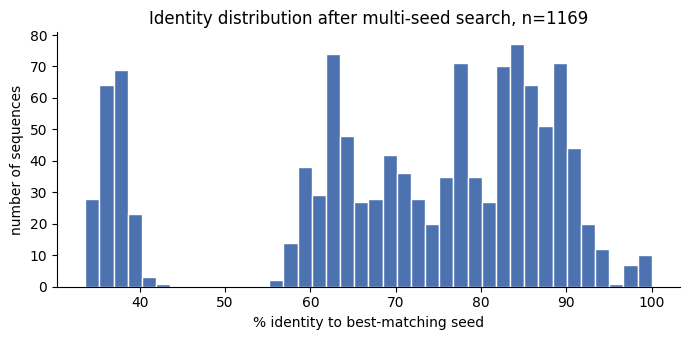

min 33.6%   median 75.9%   max 100.0%


In [17]:
import matplotlib.pyplot as plt, statistics, json

merged = json.load(open("merged_hits.json"))
idents = [h["identity"]*100 for h in merged.values()]

fig, ax = plt.subplots(figsize=(7,3.5))
ax.hist(idents, bins=40, color="#4C72B0", edgecolor="white")
ax.set_xlabel("% identity to best-matching seed")
ax.set_ylabel("number of sequences")
ax.set_title(f"Identity distribution after multi-seed search, n={len(idents)}")
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(f"min {min(idents):.1f}%   median {statistics.median(idents):.1f}%   max {max(idents):.1f}%")
if min(idents) > 55:
    print("\n*** still nothing below ~55% - the divergent end is still missing.")
    print("    Tell Claude before building the tree.")

In [18]:
!cd-hit -i homologs_raw.fasta -o homologs_nr80.fasta -c 0.80 -n 5 -M 4000 -d 0 > cdhit.log 2>&1

raw = list(SeqIO.parse("homologs_raw.fasta", "fasta"))
if os.path.exists("homologs_nr80.fasta"):
    nr = list(SeqIO.parse("homologs_nr80.fasta", "fasta"))
    print(f"cd-hit: {len(raw)} -> {len(nr)} sequences at 80% identity")
else:
    print("cd-hit unavailable; removing exact duplicates only")
    uniq, byseq = [], set()
    for r in raw:
        s = str(r.seq)
        if s not in byseq:
            byseq.add(s); uniq.append(r)
    SeqIO.write(uniq, "homologs_nr80.fasta", "fasta")
    nr = uniq
    print(f"fallback: {len(raw)} -> {len(nr)} sequences")

cd-hit: 1169 -> 159 sequences at 80% identity


In [20]:
import os, json, subprocess
from collections import Counter
from Bio import SeqIO

RAW = "homologs_raw.fasta"
OUT = "homologs_nr_balanced.fasta"

# seed -> (group name, cd-hit identity cutoff)
GROUPS = {
    "FGD1_Mtub": ("FGDlike", 0.80),
    "AncD1":     ("FGDlike", 0.80),
    "Adf_Mthe":  ("ADHlike", 0.80),
    "FSD_Noca":  ("FSDlike", 0.95),   # sparse - keep nearly all diversity
    "FSD_Cryar": ("FSDlike", 0.95),
}

merged = json.load(open("merged_hits.json"))
raw = list(SeqIO.parse(RAW, "fasta"))
print(f"{len(raw)} sequences in {RAW}")


def acc_of(rec):
    parts = rec.id.split("|")
    return parts[1] if len(parts) > 1 else rec.id.split()[0]


# ---- split by group ----
buckets, unassigned = {}, []
for r in raw:
    h = merged.get(acc_of(r))
    if not h:
        unassigned.append(r)
        continue
    g, cut = GROUPS.get(h["best_seed"], ("other", 0.80))
    buckets.setdefault((g, cut), []).append(r)

print("\ngroups before reduction:")
for (g, cut), recs in sorted(buckets.items()):
    print(f"  {g:9s} cutoff {cut:.2f}  {len(recs):5d}")
if unassigned:
    print(f"  {'unassigned':9s}              {len(unassigned):5d}  (kept as-is)")


def cdhit(recs, cutoff, tag):
    """Run cd-hit on one group; fall back to exact-duplicate removal."""
    fin, fout = f"_grp_{tag}.fasta", f"_grp_{tag}_nr.fasta"
    SeqIO.write(recs, fin, "fasta")
    n = 5 if cutoff >= 0.70 else 4
    try:
        r = subprocess.run(
            ["cd-hit", "-i", fin, "-o", fout, "-c", str(cutoff),
             "-n", str(n), "-M", "4000", "-d", "0"],
            capture_output=True, text=True,
        )
        if r.returncode == 0 and os.path.exists(fout):
            return list(SeqIO.parse(fout, "fasta"))
    except FileNotFoundError:
        pass
    print(f"    cd-hit unavailable for {tag}; removing exact duplicates only")
    seen, uniq = set(), []
    for x in recs:
        s = str(x.seq)
        if s not in seen:
            seen.add(s); uniq.append(x)
    return uniq


print("\nreducing:")
kept_all, summary = [], {}
for (g, cut), recs in sorted(buckets.items()):
    out = cdhit(recs, cut, g)
    kept_all.extend(out)
    summary[g] = (len(recs), len(out))
    print(f"  {g:9s} {len(recs):5d} -> {len(out):4d}  ({100*len(out)/len(recs):.1f}% kept)")
kept_all.extend(unassigned)

# ---- drop any duplicate accessions introduced across groups ----
seen, final = set(), []
for r in kept_all:
    a = acc_of(r)
    if a in seen:
        continue
    seen.add(a); final.append(r)

SeqIO.write(final, OUT, "fasta")
nr = final      # Step 1.5's final-set cell expects this name

print(f"\nwrote {OUT}  ({len(final)} sequences)")

fsd = summary.get("FSDlike", (0, 0))[1]
fgd = summary.get("FGDlike", (0, 0))[1]
adh = summary.get("ADHlike", (0, 0))[1]
print(f"\nFSD-like {fsd}   FGD-like {fgd}   ADH-like {adh}")
if fsd:
    print(f"ratio FGD:FSD = 1:{fgd/fsd:.1f}" if fgd < fsd else f"ratio FGD:FSD = {fgd/fsd:.1f}:1")

if fsd < 15:
    print("\n*** FSD side still under 15. Tell Claude before Stage 1b.")
elif fgd / max(fsd, 1) > 3:
    print("\n*** still over 3:1. Workable, but subsample the FGD clade in Stage 3.")
else:
    print("\nBalance is reasonable. Proceed to Step 1.5 final-set cell.")

if len(final) <= 500:
    print(f"{len(final)} sequences -> MAFFT L-INS-i in Stage 1b.")
else:
    print(f"{len(final)} sequences -> too many for L-INS-i; use FFT-NS-2.")

for f in os.listdir("."):
    if f.startswith("_grp_"):
        os.remove(f)

1169 sequences in homologs_raw.fasta

groups before reduction:
  ADHlike   cutoff 0.80    205
  FGDlike   cutoff 0.80    864
  FSDlike   cutoff 0.95    100

reducing:
  ADHlike     205 ->   62  (30.2% kept)
  FGDlike     864 ->   92  (10.6% kept)
  FSDlike     100 ->   76  (76.0% kept)

wrote homologs_nr_balanced.fasta  (230 sequences)

FSD-like 76   FGD-like 92   ADH-like 62
ratio FGD:FSD = 1.2:1

Balance is reasonable. Proceed to Step 1.5 final-set cell.
230 sequences -> MAFFT L-INS-i in Stage 1b.


## Step 1.5 — Build the final set

AncD1 + references + non-redundant homologs, with any homolog that duplicates a reference
accession dropped so nothing appears twice.

In [21]:
final = []
final.append(SeqRecord(Seq(ANCD1), id="AncD1", description="ancestral node | THIS STUDY"))
final.extend(ref_records)

ref_accs = {acc.split(".")[0] for acc, *_ in REFERENCES}
added = 0
for rec in nr:
    base = rec.id.split(".")[0]
    if base in ref_accs:
        continue
    final.append(rec); added += 1

SeqIO.write(final, "ancd1_set_final.fasta", "fasta")

print(f"FINAL SET: {len(final)} sequences")
print(f"  1 AncD1")
print(f"  {len(ref_records)} characterized references")
print(f"  {added} homologs")
print()
lens = [len(r.seq) for r in final]
print(f"length range {min(lens)}-{max(lens)} aa, median {sorted(lens)[len(lens)//2]}")
print()
if len(final) <= 500:
    print(f"-> {len(final)} sequences: use MAFFT L-INS-i for the alignment.")
else:
    print(f"-> {len(final)} sequences: too many for L-INS-i. Either tighten the")
    print("   filters above, or switch to MAFFT FFT-NS-2 / Clustal Omega.")
print()
print("wrote ancd1_set_final.fasta -- download this file, it is the input to Stage 1b.")

FINAL SET: 239 sequences
  1 AncD1
  8 characterized references
  230 homologs

length range 230-420 aa, median 335

-> 239 sequences: use MAFFT L-INS-i for the alignment.

wrote ancd1_set_final.fasta -- download this file, it is the input to Stage 1b.


In [22]:
import re
from collections import Counter

genera = Counter()
for rec in final:
    m = re.search(r"OS=([A-Z][a-z]+)", rec.description)
    genera[m.group(1) if m else "unknown"] += 1

print("Top genera in the final set:\n")
top = genera.most_common(15)
mx = max(genera.values())
for g, n in top:
    print(f"{g[:24]:24s} {n:4d}  {'#' * int(40 * n / mx)}")

first = genera.most_common(1)[0]
if first[0] != "unknown" and first[1] / len(final) > 0.4:
    print(f"\n*** {first[0]} is {100*first[1]/len(final):.0f}% of the set — tell Claude.")

Top genera in the final set:

Microbacterium             13  ########################################
Devosia                    13  ########################################
unknown                    11  #################################
Kribbella                   6  ##################
Nakamurella                 6  ##################
Candidatus                  5  ###############
Dictyobacter                5  ###############
Pseudonocardia              5  ###############
Amycolatopsis               5  ###############
Nocardioides                5  ###############
Methanosarcina              4  ############
Jatrophihabitans            4  ############
Agromyces                   4  ############
Kineococcus                 4  ############
Cryptosporangium            4  ############


In [23]:
from google.colab import files
files.download("ancd1_set_final.fasta")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from google.colab import files
files.download("merged_hits.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from google.colab import files
files.download("homologs_nr_balanced.fasta")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

## Checkpoint — look at these before continuing

1. **How many sequences?** This determines the aligner (see the message above).
2. **Did all 9 references download?** Re-run Step 1.2 if any failed. The tree is
   uninterpretable without them.
3. **Is the identity histogram a spread or a spike?** A spike means re-run the search.
4. **Taxonomic breadth** — run the cell below. If it's 90% *Mycobacterium*, the tree will
   be lopsided and the Stage 3 clade comparison will be weak.

In [26]:
import re
from collections import Counter

genera = Counter()
for rec in final:
    m = re.search(r"\[([A-Z][a-z]+)", rec.description)
    genera[m.group(1) if m else "unknown"] += 1

print("Top genera in the final set:\n")
for g, n in genera.most_common(15):
    bar = "#" * int(40 * n / max(genera.values()))
    print(f"{g[:24]:24s} {n:4d}  {bar}")

top = genera.most_common(1)[0]
if top[1] / len(final) > 0.4 and top[0] != "unknown":
    print(f"\n*** {top[0]} is {100*top[1]/len(final):.0f}% of the set.")
    print("    Consider a stricter cd-hit cutoff (0.80) to rebalance.")

Top genera in the final set:

unknown                   239  ########################################
